## Customer_Churn_Analysis

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("customer churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True) *100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [63]:
df.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76,2279.73
std,0.37,24.56,30.09,2266.79
min,0.00,0.00,18.25,0.00
25%,0.00,9.00,35.50,398.55
50%,0.00,29.00,70.35,1394.55
75%,0.00,55.00,89.85,3786.60
max,1.00,72.00,118.75,8684.80


In [16]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [17]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],errors="coerce"
)

In [18]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [20]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["TotalCharges"].isnull().sum()

np.int64(0)

In [21]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

In [22]:
df.shape

(7043, 21)

In [23]:
churn_counts = df["Churn"].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


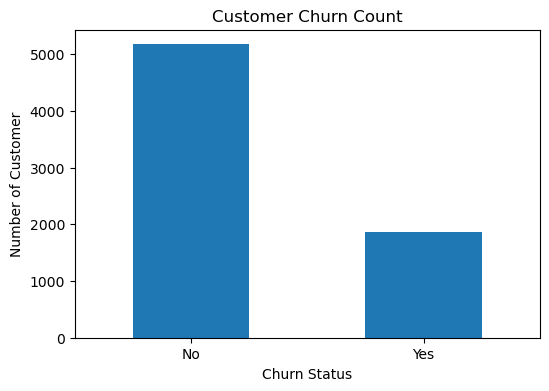

In [25]:
import matplotlib.pyplot as plt
churn_counts = df["Churn"].value_counts()
plt.figure(figsize=(6,4))
churn_counts.plot(kind="bar")
plt.title("Customer Churn Count")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customer")
plt.xticks(rotation=0)
plt.show()

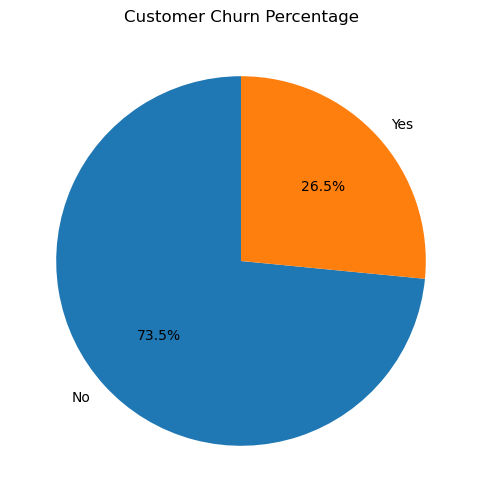

In [26]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
plt.figure(figsize=(6,6))
plt.pie(churn_percentage,
       labels=churn_percentage.index,
       autopct="%1.1f%%",
       startangle=90
)
plt.title("Customer Churn Percentage")
plt.show()

In [27]:
contract_churn = df.groupby(
    ["Contract","Churn"]
).size().unstack()
print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [29]:
contract_churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x:(x == "Yes").mean() * 100)
)
print(contract_churn_rate)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


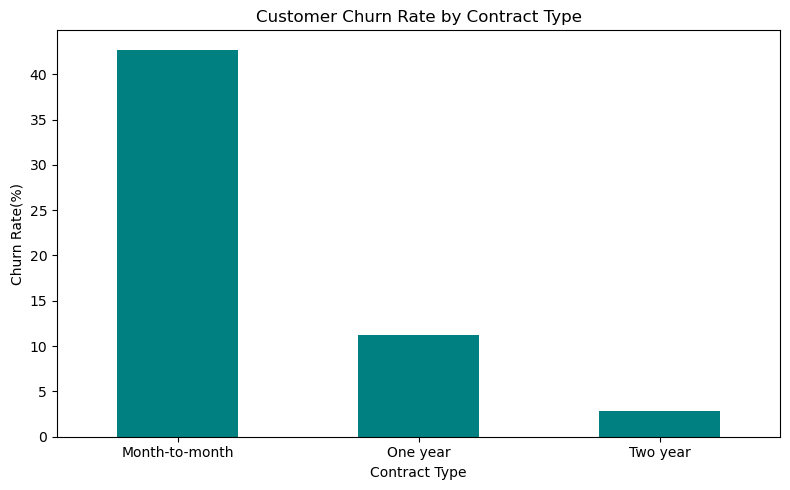

In [32]:
plt.figure(figsize=(8,5)) 
contract_churn_rate.plot(kind="bar",color="teal")
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [33]:
average_tenure = df.groupby("Churn")["tenure"].mean()
print(average_tenure)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


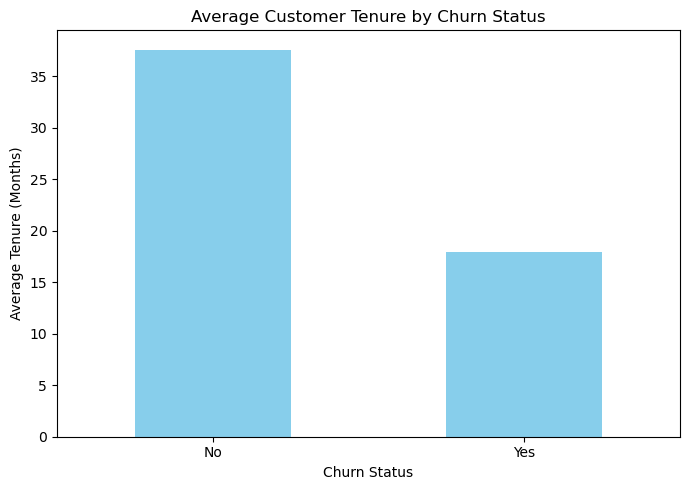

In [35]:
plt.figure(figsize=(7,5))
average_tenure.plot(kind="bar",color="skyblue")
plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [36]:
average_monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()
print(average_monthly_charges)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


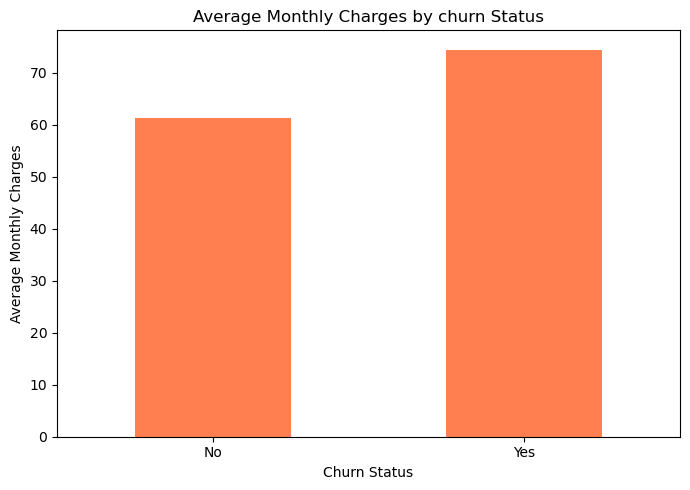

In [37]:
plt.figure(figsize=(7,5))
average_monthly_charges.plot(kind="bar",color="coral")
plt.title("Average Monthly Charges by churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [38]:
payment_churn = df.groupby(
    ["PaymentMethod","Churn"]
).size().unstack()
print(payment_churn)

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308


In [39]:
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean()*100)
)
print(payment_churn_rate)

PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: Churn, dtype: float64


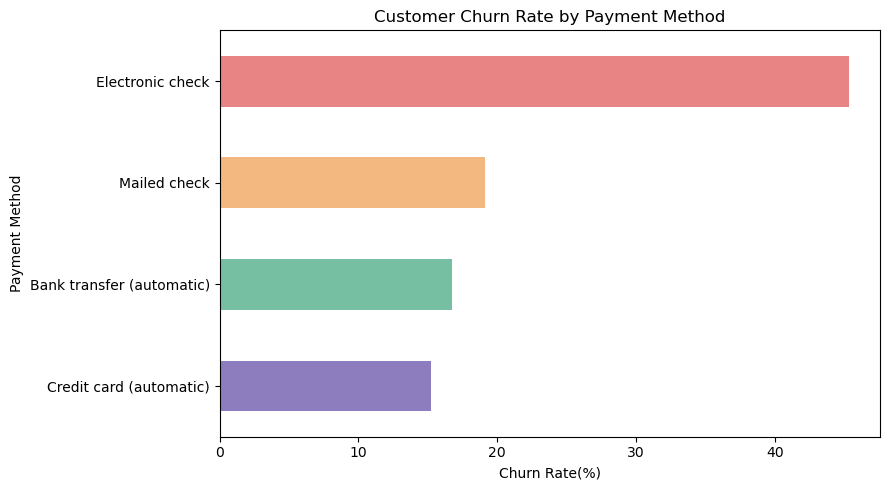

In [40]:
plt.figure(figsize=(9,5))
payment_churn_rate.sort_values().plot(
    kind="barh", color=["#8E7DBE", "#77BFA3", "#F2B880", "#E88484"]
)
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate(%)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()

In [41]:
internet_churn = df.groupby(
    ["InternetService","Churn"]
).size().unstack()
print(internet_churn)

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


In [42]:
internet_churn_rate=(
    df.groupby("InternetService")["Churn"]
    .apply(lambda x:(x == "Yes").mean() * 100)
)
print(internet_churn_rate)

InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64


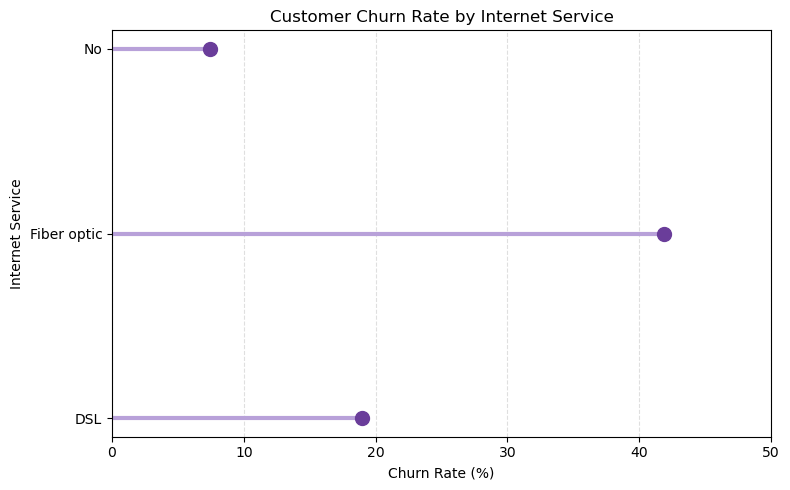

In [45]:
plt.figure(figsize=(8, 5))
plt.hlines(
    y=internet_churn_rate.index,
    xmin=0,
    xmax=internet_churn_rate.values,
    color="#B8A1D9",
    linewidth=3
)
plt.plot(
    internet_churn_rate.values,
    internet_churn_rate.index,
    "o",
    color="#6A3D9A",
    markersize=10
)
plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Internet Service")
plt.xlim(0, 50)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [47]:
senior_churn = df.groupby(
    ["SeniorCitizen","Churn"]
).size().unstack()
print(senior_churn)

Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476


In [48]:
senior_churn_rate=(
    df.groupby("SeniorCitizen")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print(senior_churn_rate)

SeniorCitizen
0    23.606168
1    41.681261
Name: Churn, dtype: float64


In [50]:
gender_churn_rate = (
    df.groupby("gender")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print(gender_churn_rate)

gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64


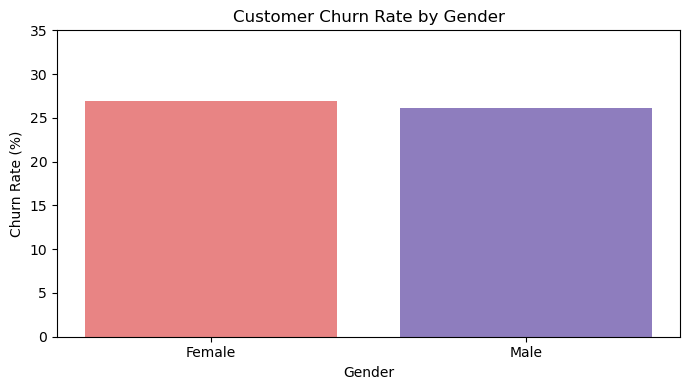

In [60]:
plt.figure(figsize=(7, 4))
plt.bar(
    gender_churn_rate.index,
    gender_churn_rate.values,
    color=["#E88484", "#8E7DBE"]
)
plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 35)
plt.tight_layout()
plt.show()

In [54]:
paperless_churn_rate = (
    df.groupby("PaperlessBilling")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print(paperless_churn_rate)

PaperlessBilling
No     16.330084
Yes    33.565092
Name: Churn, dtype: float64


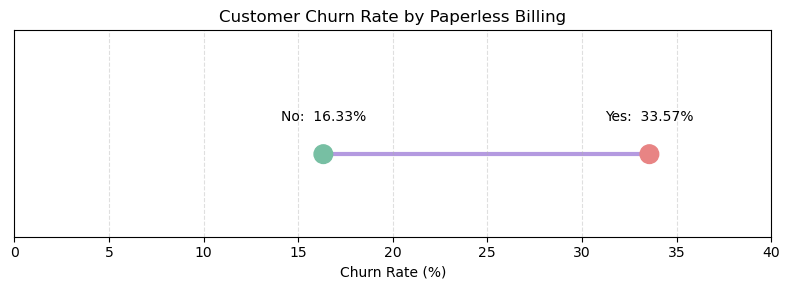

In [62]:
plt.figure(figsize=(8,3))
values = paperless_churn_rate.values
labels = paperless_churn_rate.index
plt.plot(values,[0,0],
        color = "#B49AE0",
        linewidth=3,
        zorder=1
)
plt.scatter(values,[0,0],
           color = ["#77BFA3", "#E88484"],
           s=180,
           zorder=2
)
for x,label in zip(values,labels):
    plt.text(x,0.08,f"{label}: {x: .2f}%", ha="center")
plt.title("Customer Churn Rate by Paperless Billing")
plt.xlabel("Churn Rate (%)")
plt.yticks([])
plt.xlim(0,40)
plt.ylim(-0.2,0.3)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [57]:
df["TenureGroup"] = pd.cut(
    df["tenure"],bins=[-1,12,24,48,72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)
tenure_churn_rate =(
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x:(x == "Yes").mean() * 100)
)
print(tenure_churn_rate)

TenureGroup
0-12 Months     47.438243
13-24 Months    28.710938
25-48 Months    20.388959
49-72 Months     9.513176
Name: Churn, dtype: float64


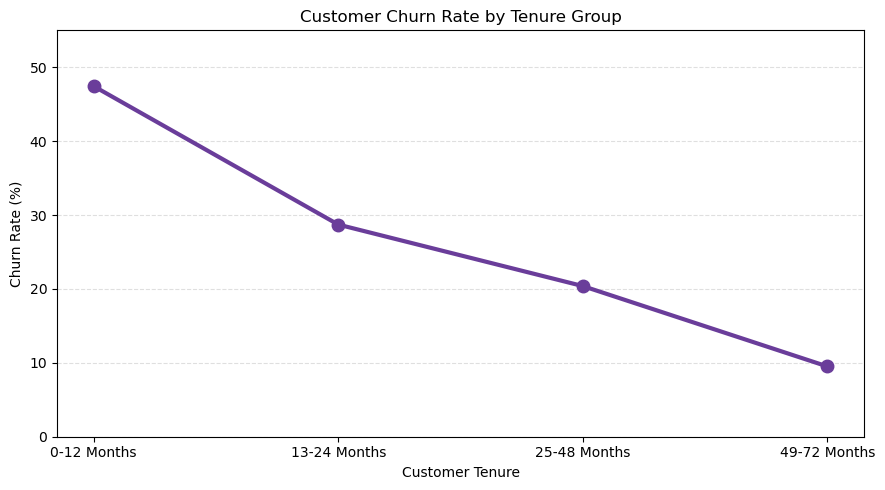

In [58]:
plt.figure(figsize=(9, 5))
plt.plot(
    tenure_churn_rate.index.astype(str),
    tenure_churn_rate.values,
    marker="o",
    color="#6A3D9A",
    linewidth=3,
    markersize=9
)
plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 55)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [59]:
total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
overall_churn_rate = (churned_customers/total_customers) * 100
average_monthly_charges = df["MonthlyCharges"].mean()
print("Total Customers:",total_customers)
print("Churned Customers:",churned_customers)
print("Overall Churn Rate:",round(overall_churn_rate,2),"%")
print("Average Monthly Charges:",round(average_monthly_charges,2))

Total Customers: 7043
Churned Customers: 1869
Overall Churn Rate: 26.54 %
Average Monthly Charges: 64.76


## Key Business Insights

1. **Overall churn:** 1,869 out of 7,043 customers left the company, representing a churn rate of 26.54%.

2. **Contract type:** Month-to-month customers have the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

3. **Customer tenure:** Customers in their first 12 months have a churn rate of 47.44%, while customers with 49–72 months of tenure have a churn rate of only 9.51%.

4. **Monthly charges:** Customers who churn have higher average monthly charges ($74.44) than customers who stay ($61.27).

5. **Internet service:** Fiber-optic customers have a churn rate of 41.89%, compared with 18.96% for DSL customers.

6. **Payment method:** Customers using electronic checks have the highest churn rate at 45.29%.

7. **Senior citizens:** Senior customers have a churn rate of 41.68%, compared with 23.61% for non-senior customers.

8. **Paperless billing:** Customers using paperless billing have a churn rate of 33.57%, compared with 16.33% for customers not using it.

## Business Recommendations

- Improve onboarding and customer support during the first year.
- Encourage suitable longer-term contracts through customer-friendly offers.
- Investigate why electronic-check and fiber-optic customers leave more frequently.
- Review pricing, service quality, and customer satisfaction among customers with high monthly charges.
- Develop targeted retention strategies for customer groups with higher churn rates.

## Conclusion

This analysis identifies customer groups associated with higher churn and highlights opportunities to improve retention. The findings can help a telecom company prioritize customer support and investigate the factors associated with customer departures.